# 04 — Preparação para Modelagem (BTC & ETH, 2 anos)

Este notebook parte do `03_Analise_Consolidada` e entrega o **dataset de modelagem**, com alvos sem vazamento, partições temporais e uma bateria de verificações. Nenhuma conclusão está escrita à mão: tudo o que é interpretação sai de números calculados nas células.

## O que foi corrigido em relação ao 03

| # | Problema no 03 | Correção no 04 |
|---|---|---|
| 1 | Alvo de RV com `shift(-h)`: para h>1 a janela ficava em `t+h … t+2h−1` | `shift(-1)` + teste automático contra o cálculo manual |
| 2 | Grade com 1 hora de defasagem em relação ao mercado | Grade construída a partir do próprio mercado, com merges `one_to_one` |
| 3 | RV usada mesmo com candles faltando ou RV = 0 | RV inválida (`n_5m ≠ 12` ou `RV ≤ 0`) vira `NaN` |
| 4 | `log1p` em taxas de ~0,1 gwei (não comprime a cauda) | `log` puro, com zeros tratados como ausentes |
| 5 | Poisson só comparava médias | Teste de dispersão e qui-quadrado de aderência |
| 6 | Lead-lag com Pearson em níveis e texto fixo "comprovado" | Pré-branqueamento (resíduos AR) + Granger com erros robustos (HAC) |
| 7 | Estudo de evento com 1 episódio e título fixo | Top-N eventos de RV (sem sobreposição) com **placebo** pareado por hora do dia |
| 8 | Lift contemporâneo, limiar da amostra inteira, sem incerteza | Limiar só do passado, alvo futuro, IC por bootstrap em blocos e permutação estratificada |
| 9 | Split único 80/20 | *Holdout* final bloqueado + *walk-forward* com embargo |
| 10 | Fear & Greed tratado como 17.520 observações | Análise no nível diário (n = dias) e checagem de circularidade |

## O que foi adicionado

- **Alvos do Modelo B** (taxa alta e congestionamento), com limiar relativo ao **passado recente** (robusto a mudanças de regime) e duas definições de evento.
- **Teste de vazamento por perturbação**: altera os dados futuros e verifica que nenhuma feature passada muda.
- **Escada de modelos de volatilidade** HAR → +calendário → +mercado → +on-chain → +Fear & Greed, com QLIKE, Diebold–Mariano (HAC) e correção de Holm.

## Regras de ouro deste notebook

1. **O *holdout* (últimos 90 dias) não é usado em nenhuma análise inferencial.** Só o conjunto de desenvolvimento (`dev`) é explorado.
2. A coluna `hora` marca o **início** da janela; os dados da linha só existem em `hora + 1h`. Os alvos olham de `t+1` em diante.
3. Resultado nulo é resultado: se on-chain e sentimento não melhorarem o HAR, é isso que as tabelas vão mostrar.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10

# ------------------- CAMINHOS (ajuste se necessário) -------------------
PASTA_BASE = Path("/home/alisson/datathon fgv")
PASTA_DADOS = PASTA_BASE / "Análises"
PASTA_2ANOS = PASTA_BASE / "dados_cripto" / "historico_2anos"
PASTA_BIGQUERY = PASTA_BASE / "dados_cripto" / "Big_query"
PASTA_SAIDA = PASTA_DADOS / "modelagem"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

ARQUIVOS = {
    "mercado":    PASTA_2ANOS / "mercado_horario_agregado.csv",
    "btc_blocos": PASTA_BIGQUERY / "btc_blocos_hora(2).csv",
    "btc_tx":     PASTA_BIGQUERY / "btc_transacoes_hora(2).csv",
    "eth_blocos": PASTA_BIGQUERY / "eth_blocos_hora(2).csv",
    "eth_tx":     PASTA_BIGQUERY / "eth_transacoes_hora(2).csv",
    "fng":        PASTA_DADOS / "fear_greed_completo.csv",
}

# ------------------- PARÂMETROS METODOLÓGICOS -------------------
HORIZONTES_VOL = [1, 4, 12, 24]      # alvos de volatilidade (horas)
HORIZONTES_TAXA = [1, 6]             # alvos de taxa (horas)
JANELA_REF_H = 24 * 30               # janela do limiar (passado): 30 dias
Q_ALTO = 0.90                        # quantil para "taxa alta" / "vol alta"
MULT_MEDIANA = 2.0                   # evento alternativo: >= 2x a mediana dos últimos 7 dias
EMBARGO_H = max(HORIZONTES_VOL)      # lacuna entre treino e teste
HOLDOUT_DIAS = 90                    # bloqueado: não usar em análise inferencial
TREINO_INICIAL_DIAS = 365
TESTE_BLOCO_DIAS = 30
PASSO_DIAS = 30
N_EVENTOS = 40                       # estudo de evento: nº de explosões de RV
B_BOOT, B_PERM = 500, 500            # réplicas de bootstrap e permutação
SEMENTE = 42
rng = np.random.default_rng(SEMENTE)

SERIES_TAXA = {"btc": "btc_bq_taxa_p50_sat_vb", "eth": "eth_bq_base_fee_media_gwei"}
print("Configuração carregada. Holdout:", HOLDOUT_DIAS, "dias | Embargo:", EMBARGO_H, "h")

/home/alisson/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Configuração carregada. Holdout: 90 dias | Embargo: 24 h


## 1. Carga, grade horária e relatório de qualidade

A grade vem do **próprio mercado** (de `min` a `max` da coluna `hora`), com `validate="one_to_one"` em todos os merges. Horas ausentes nas fontes do BigQuery ficam como `NaN` e são tratadas explicitamente adiante.

In [2]:
def ler_hora(caminho):
    df = pd.read_csv(caminho)
    df["hora"] = pd.to_datetime(df["hora"], utc=True).astype("datetime64[ns, UTC]")
    if df["hora"].duplicated().any():
        raise ValueError(f"Horas duplicadas em {Path(caminho).name}")
    return df

nomes_horarios = ["mercado", "btc_blocos", "btc_tx", "eth_blocos", "eth_tx"]
brutos = {k: ler_hora(ARQUIVOS[k]) for k in nomes_horarios}
fng_raw = pd.read_csv(ARQUIVOS["fng"])

mercado = brutos["mercado"]
grade = pd.DataFrame({"hora": pd.date_range(mercado["hora"].min(), mercado["hora"].max(), freq="h")})
grade["hora"] = grade["hora"].astype("datetime64[ns, UTC]")

raw = grade.copy()
for nome in nomes_horarios:
    raw = raw.merge(brutos[nome], on="hora", how="left", validate="one_to_one")
raw = raw.sort_values("hora").reset_index(drop=True)

rel = []
for nome, df in brutos.items():
    na_grade = int(df["hora"].isin(grade["hora"]).sum())
    rel.append({"fonte": nome, "linhas": len(df), "na_grade": na_grade,
                "fora_da_grade": len(df) - na_grade, "horas_da_grade_sem_dado": len(grade) - na_grade})
print(f"Grade: {len(grade):,} horas | {grade['hora'].min()} -> {grade['hora'].max()}")
print("Lacunas na grade do mercado:", len(grade) - len(mercado), "hora(s)")
display(pd.DataFrame(rel))

# ---- Validade da volatilidade realizada: 12 retornos de 5 min e RV > 0 ----
for a in ("btc", "eth"):
    n5 = raw[f"{a}_n_5m"]
    invalida_n = (n5 != 12) & n5.notna()
    invalida_zero = (raw[f"{a}_rv"] <= 0)
    valida = (n5 == 12) & (raw[f"{a}_rv"] > 0)
    raw[f"{a}_rv_valida"] = valida
    raw[f"{a}_rv"] = raw[f"{a}_rv"].where(valida)
    print(f"{a.upper()}: horas com n_5m != 12: {int(invalida_n.sum())} | RV <= 0: {int(invalida_zero.sum())} "
          f"| RV válida: {int(valida.sum()):,} ({valida.mean()*100:.2f}%)")

Grade: 17,520 horas | 2024-11-03 00:00:00+00:00 -> 2026-11-02 23:00:00+00:00
Lacunas na grade do mercado: 0 hora(s)


,fonte,linhas,na_grade,fora_da_grade,horas_da_grade_sem_dado
0,mercado,17520,17520,0,0
1,btc_blocos,17477,17476,1,44
2,btc_tx,17477,17476,1,44
3,eth_blocos,17520,17519,1,1
4,eth_tx,17520,17519,1,1


BTC: horas com n_5m != 12: 1 | RV <= 0: 1 | RV válida: 17,519 (99.99%)
ETH: horas com n_5m != 12: 1 | RV <= 0: 1 | RV válida: 17,519 (99.99%)


## 2. Diagnóstico das redes (com testes, sem texto pré-escrito)

- **Bitcoin:** chegada de blocos vs. Poisson (dispersão e aderência), horas sem bloco e ocupação do bloco.
- **Ethereum:** uso de gás vs. meta de 50%, **limite de gás implícito ao longo do tempo** (se mudou, `gas_total` não é comparável entre períodos) e regimes de taxa por trimestre.

In [3]:
# ---------------- BITCOIN: Poisson ----------------
blocos = raw["btc_bq_blocos"].fillna(0)          # hora ausente no BigQuery = 0 blocos
n = len(blocos)
lam = blocos.mean()
disp = blocos.var(ddof=1) / lam
chi_disp = (n - 1) * disp
p_disp = stats.chi2.sf(chi_disp, n - 1)          # H1: sobredispersão

kmax = 15
obs = np.array([(blocos == k).sum() for k in range(kmax)] + [(blocos >= kmax).sum()], float)
esp = np.array([stats.poisson.pmf(k, lam) for k in range(kmax)] + [stats.poisson.sf(kmax - 1, lam)]) * n
obs_l, esp_l = list(obs), list(esp)
while len(esp_l) > 2 and (esp_l[0] < 5 or esp_l[-1] < 5):      # funde as pontas até esperado >= 5
    if esp_l[0] < esp_l[-1]:
        obs_l[1] += obs_l[0]; esp_l[1] += esp_l[0]; obs_l.pop(0); esp_l.pop(0)
    else:
        obs_l[-2] += obs_l[-1]; esp_l[-2] += esp_l[-1]; obs_l.pop(); esp_l.pop()
obs_g, esp_g = np.array(obs_l), np.array(esp_l)
chi_gof = ((obs_g - esp_g) ** 2 / esp_g).sum()
gl = len(obs_g) - 1 - 1                           # -1 pelo λ estimado
p_gof = stats.chi2.sf(chi_gof, gl)

raw["btc_hora_sem_bloco"] = (blocos == 0).astype(int)
print("=== BITCOIN: chegada de blocos ===")
print(f"λ (blocos/hora) = {lam:.3f} | variância/média = {disp:.3f}")
print(f"Teste de sobredispersão: χ² = {chi_disp:,.1f} (gl={n-1:,}) | p = {p_disp:.4g}")
print(f"Aderência ao Poisson:    χ² = {chi_gof:,.1f} (gl={gl}) | p = {p_gof:.4g}")
print(f"Horas sem bloco: observadas = {int((blocos == 0).sum())} | esperadas sob Poisson = {n*np.exp(-lam):.1f}")
print("Obs.: rejeição indica heterogeneidade (hashrate/dificuldade variam); ver variação por trimestre abaixo.")

trim = raw.assign(b=blocos).set_index("hora")["b"].resample("QS").agg(["mean", "var"])
trim["var/mean"] = trim["var"] / trim["mean"]
display(trim.round(3))

# ---------------- BITCOIN: ocupação ----------------
oc = raw["btc_bq_ocupacao_media"]
print("\nOcupação do bloco BTC (quantis):")
print(oc.quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.95]).round(4).to_string())
bucket = pd.cut(blocos, [-1, 2, 5, 8, 100], labels=["0-2", "3-5", "6-8", "9+"])
print("\nOcupação média por nº de blocos na hora:")
print(oc.groupby(bucket, observed=True).mean().round(4).to_string())

=== BITCOIN: chegada de blocos ===
λ (blocos/hora) = 6.033 | variância/média = 1.002
Teste de sobredispersão: χ² = 17,559.4 (gl=17,519) | p = 0.4133
Aderência ao Poisson:    χ² = 12.9 (gl=14) | p = 0.534
Horas sem bloco: observadas = 44 | esperadas sob Poisson = 42.0
Obs.: rejeição indica heterogeneidade (hashrate/dificuldade variam); ver variação por trimestre abaixo.


,mean,var,var/mean
hora,,,
2024-10-01 00:00:00+00:00,6.100,5.495,0.901
2025-01-01 00:00:00+00:00,6.049,5.924,0.979
2025-04-01 00:00:00+00:00,6.012,5.872,0.977
2025-07-01 00:00:00+00:00,6.202,6.246,1.007
2025-10-01 00:00:00+00:00,5.975,5.930,0.992
2026-01-01 00:00:00+00:00,5.921,6.078,1.026
2026-04-01 00:00:00+00:00,5.957,6.162,1.034
2026-07-01 00:00:00+00:00,5.991,6.287,1.049
2026-10-01 00:00:00+00:00,6.240,6.410,1.027



Ocupação do bloco BTC (quantis):
0.05    0.7456
0.10    0.8209
0.25    0.9386
0.50    0.9984
0.75    0.9985
0.95    0.9988

Ocupação média por nº de blocos na hora:
btc_bq_blocos
0-2    0.9893
3-5    0.9718
6-8    0.9434
9+     0.9060


=== ETHEREUM: uso de gás ===
gas_ratio: média = 0.5059 | desvio = 0.0072 | max = 0.6015 (meta EIP-1559 = 0,50)


,limite_gas_implicito (M)
hora,
2024-10-01 00:00:00+00:00,30.0
2025-01-01 00:00:00+00:00,35.9
2025-04-01 00:00:00+00:00,36.0
2025-07-01 00:00:00+00:00,45.0
2025-10-01 00:00:00+00:00,45.0
2026-01-01 00:00:00+00:00,60.0
2026-04-01 00:00:00+00:00,60.0
2026-07-01 00:00:00+00:00,60.0
2026-10-01 00:00:00+00:00,60.0


AVISO: o limite de gás implícito mudou mais de 10% no período -> use gas_ratio (normalizado), não gas_total.

Regimes de taxa por trimestre:


,BTC p50 (sat/vB) | mediana,BTC p50 (sat/vB) | p95,ETH base fee (gwei) | mediana,ETH base fee (gwei) | p95
hora,,,,
2024-10-01 00:00:00+00:00,6.554,17.348,11.313,33.419
2025-01-01 00:00:00+00:00,3.016,8.000,1.201,17.988
2025-04-01 00:00:00+00:00,3.000,6.000,0.842,6.632
2025-07-01 00:00:00+00:00,2.000,5.000,0.401,4.140
2025-10-01 00:00:00+00:00,1.199,4.000,0.114,1.400
2026-01-01 00:00:00+00:00,1.199,3.862,0.060,0.471
2026-04-01 00:00:00+00:00,1.000,4.000,0.166,1.609
2026-07-01 00:00:00+00:00,0.540,3.978,0.093,0.715
2026-10-01 00:00:00+00:00,0.286,3.563,0.090,0.888


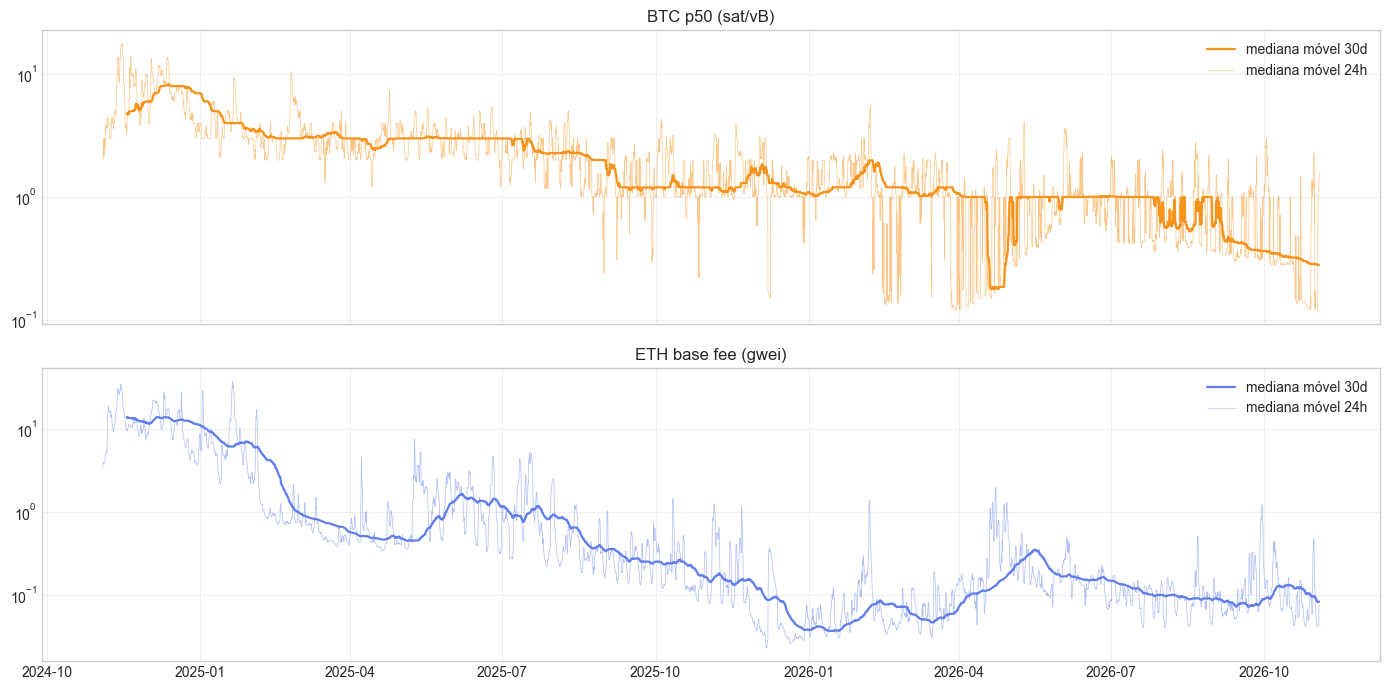

In [4]:
# ---------------- ETHEREUM: gás e regimes ----------------
gr = raw["eth_bq_gas_ratio_medio"]
print("=== ETHEREUM: uso de gás ===")
print(f"gas_ratio: média = {gr.mean():.4f} | desvio = {gr.std():.4f} | max = {gr.max():.4f} (meta EIP-1559 = 0,50)")

raw["eth_gas_limit_implicito"] = raw["eth_bq_gas_total"] / (raw["eth_bq_blocos"] * raw["eth_bq_gas_ratio_medio"])
lim_tri = (raw.set_index("hora")["eth_gas_limit_implicito"].resample("QS").median() / 1e6).rename("limite_gas_implicito (M)")
display(lim_tri.round(1).to_frame())
if lim_tri.max() / lim_tri.min() > 1.10:
    print("AVISO: o limite de gás implícito mudou mais de 10% no período -> use gas_ratio (normalizado), não gas_total.")

# regimes de taxa por trimestre
cols_reg = {"btc_bq_taxa_p50_sat_vb": "BTC p50 (sat/vB)", "eth_bq_base_fee_media_gwei": "ETH base fee (gwei)"}
reg = raw.set_index("hora")[list(cols_reg)].rename(columns=cols_reg).resample("QS").agg(["median", lambda s: s.quantile(0.95)])
reg.columns = [f"{a} | {'mediana' if b == 'median' else 'p95'}" for a, b in reg.columns]
print("\nRegimes de taxa por trimestre:")
display(reg.round(3))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, (c, nome), cor in zip(axes, cols_reg.items(), ["#F7931A", "#627EEA"]):
    s = raw.set_index("hora")[c]
    ax.plot(s.index, s.rolling(24 * 30, min_periods=24 * 15).median(), color=cor, lw=1.6, label="mediana móvel 30d")
    ax.plot(s.index, s.rolling(24, min_periods=12).median(), color=cor, lw=0.5, alpha=0.5, label="mediana móvel 24h")
    ax.set_yscale("log"); ax.set_title(nome); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 3. Construção das variáveis

Toda feature é calculada com janelas que **terminam em `t`** (nada de `shift` negativo). O preenchimento das horas sem bloco no Bitcoin é causal (`ffill` com limite de 12 h) e a flag `btc_hora_sem_bloco` preserva a informação. Logs usam `np.log` (valores ≤ 0 viram `NaN`).

O Fear & Greed entra com **defasagem de 1 dia**, construída sobre um calendário diário completo (para que o `shift` seja realmente de um dia, mesmo se faltar alguma data).

In [5]:
def log_pos(s):
    return np.log(s.where(s > 0))

def rms_rolling(rv, janela):
    # raiz da média dos RV² (escala de volatilidade) em janela que termina em t
    return np.sqrt((rv ** 2).rolling(janela, min_periods=int(0.75 * janela)).mean())

def preparar_fng(fng_raw):
    f = fng_raw.copy()
    f["data"] = pd.to_datetime(f["ts"], utc=True).dt.floor("D").astype("datetime64[ns, UTC]")
    f["fng_valor"] = pd.to_numeric(f["fng_valor"], errors="coerce")
    f = f.sort_values("data").drop_duplicates("data").set_index("data")
    idx = pd.date_range(f.index.min(), f.index.max(), freq="D")
    f = f.reindex(idx)
    out = pd.DataFrame(index=idx)
    out["fng_lag1"] = f["fng_valor"].shift(1)                    # valor do dia anterior
    out["fng_var7"] = out["fng_lag1"] - out["fng_lag1"].shift(7)
    out["fng_class_lag1"] = f["value_classification"].shift(1)
    out.index.name = "data"
    out = out.reset_index()
    out["data"] = out["data"].astype("datetime64[ns, UTC]")
    return out

def construir_features(raw_df, fng_d):
    df = raw_df.copy()
    # preenchimento causal das horas sem bloco (BTC)
    cols_ff = [c for c in df.columns if c.startswith("btc_bq_taxa")] + ["btc_bq_tx", "btc_bq_vsize_total", "btc_bq_ocupacao_media"]
    df[cols_ff] = df[cols_ff].ffill(limit=12)

    for a in ("btc", "eth"):
        rv = df[f"{a}_rv"]
        df[f"{a}_lrv"] = log_pos(rv)
        df[f"{a}_lrv_d"] = log_pos(rms_rolling(rv, 24))
        df[f"{a}_lrv_w"] = log_pos(rms_rolling(rv, 168))
        vol = df[f"{a}_volume_quote"]
        df[f"{a}_lvol"] = log_pos(vol)
        df[f"{a}_lvol_rel"] = df[f"{a}_lvol"] - log_pos(vol.rolling(168, min_periods=126).mean())
        lp = np.log(df[f"{a}_fechamento"].where(df[f"{a}_fechamento"] > 0))
        df[f"{a}_ret_1h"] = lp.diff()
        df[f"{a}_ret_24h"] = lp.diff(24)
        df[f"{a}_ret_neg_24h"] = df[f"{a}_ret_24h"].clip(upper=0)

    # on-chain BTC
    p50 = df["btc_bq_taxa_p50_sat_vb"]
    df["btc_lfee_p50"] = log_pos(p50)
    df["btc_lfee_p90"] = log_pos(df["btc_bq_taxa_p90_sat_vb"])
    df["btc_lvsize"] = log_pos(df["btc_bq_vsize_total"])
    df["btc_ltx"] = log_pos(df["btc_bq_tx"])
    df["btc_lfee_chg6"] = df["btc_lfee_p50"] - df["btc_lfee_p50"].shift(6)
    df["btc_lfee_rel30d"] = df["btc_lfee_p50"] - log_pos(p50.rolling(720, min_periods=360).median())

    # on-chain ETH
    base = df["eth_bq_base_fee_media_gwei"]
    df["eth_lbase"] = log_pos(base)
    df["eth_lprio"] = log_pos(df["eth_bq_preco_gas_p50_gwei"])
    df["eth_gas_ratio_c"] = df["eth_bq_gas_ratio_medio"] - 0.5
    df["eth_ltx"] = log_pos(df["eth_bq_tx"])
    df["eth_lbase_chg6"] = df["eth_lbase"] - df["eth_lbase"].shift(6)
    df["eth_lbase_rel30d"] = df["eth_lbase"] - log_pos(base.rolling(720, min_periods=360).median())

    # custos padronizados (descritivos)
    df["btc_custo_usd"] = p50 * 141 / 1e8 * df["btc_fechamento"]
    df["eth_custo_usd"] = df["eth_bq_preco_gas_p50_gwei"] * 21000 / 1e9 * df["eth_fechamento"]

    # calendário
    h = df["hora"].dt.hour
    df["cal_sin"] = np.sin(2 * np.pi * h / 24)
    df["cal_cos"] = np.cos(2 * np.pi * h / 24)
    df["cal_fim_semana"] = (df["hora"].dt.dayofweek >= 5).astype(int)

    # Fear & Greed (defasagem de 1 dia, já no calendário diário)
    df["_dia"] = df["hora"].dt.floor("D").astype("datetime64[ns, UTC]")
    df = df.merge(fng_d, left_on="_dia", right_on="data", how="left", validate="many_to_one")
    df = df.drop(columns=["_dia", "data"])
    return df

fng_d = preparar_fng(fng_raw)
feat = construir_features(raw, fng_d)
print("Features construídas:", feat.shape[1], "colunas |", len(feat), "linhas")
print("Dias de F&G:", len(fng_d), "| período:", fng_d["data"].min().date(), "->", fng_d["data"].max().date())

Features construídas: 78 colunas | 17520 linhas
Dias de F&G: 3197 | período: 2018-02-01 -> 2026-11-02


## 4. Alvos

**Modelo A (volatilidade):** $RV_{t,h}=\sqrt{\sum_{k=1}^{h} RV_{t+k}^2}$, com janela `t+1 … t+h` (o erro do 03 estava aqui). O alvo de modelagem é `log(RV)`.

**Modelo B (taxa/congestionamento):** para cada rede, a série de referência é a taxa p50 (BTC, sat/vB) e a base fee (ETH, gwei). Dois eventos, **ambos calculados só com o passado**:

- `ev_q`: o máximo da taxa em `t+1 … t+h` supera o **quantil 90 dos últimos 30 dias** (inclui `t`, termina em `t`);
- `ev_x`: o máximo supera **2 × a mediana dos últimos 7 dias**.

O limiar móvel torna o evento robusto a mudanças de regime (ex.: mudança no piso de taxas ou no limite de gás), o que um P90 fixo da amostra de treino não é.

In [6]:
def alvo_vol_futura(rv, h):
    # soma dos RV² em t+1 ... t+h  (shift(-1) e depois janela de tamanho h)
    soma = (rv ** 2).shift(-1).iloc[::-1].rolling(h, min_periods=h).sum().iloc[::-1]
    return np.sqrt(soma)

def max_futuro(x, h):
    return x.shift(-1).iloc[::-1].rolling(h, min_periods=h).max().iloc[::-1]

def construir_alvos(df):
    out = df.copy()
    for a in ("btc", "eth"):
        rv = out[f"{a}_rv"]
        for h in HORIZONTES_VOL:
            rvf = alvo_vol_futura(rv, h)
            out[f"{a}_rv_futura_{h}h"] = rvf
            out[f"y_{a}_lrv_{h}h"] = log_pos(rvf)

        # "vol alta" (informação até t): RV acima do quantil móvel do passado
        ref_rv = rv.rolling(JANELA_REF_H, min_periods=JANELA_REF_H // 2).quantile(Q_ALTO)
        out[f"{a}_vol_alta"] = (rv > ref_rv).astype(float).where(rv.notna() & ref_rv.notna())

        x = out[SERIES_TAXA[a]]
        ref_q = x.rolling(JANELA_REF_H, min_periods=JANELA_REF_H // 2).quantile(Q_ALTO)
        ref_med = x.rolling(168, min_periods=84).median()
        out[f"{a}_taxa_ref_q"] = ref_q
        out[f"{a}_taxa_ref_med7d"] = ref_med
        for h in HORIZONTES_TAXA:
            fmax = max_futuro(x, h)
            out[f"y_{a}_lfee_max_{h}h"] = log_pos(fmax)
            ok_q = fmax.notna() & ref_q.notna()
            ok_x = fmax.notna() & ref_med.notna()
            out[f"y_{a}_ev_q_{h}h"] = (fmax > ref_q).astype(float).where(ok_q)
            out[f"y_{a}_ev_x_{h}h"] = (fmax >= MULT_MEDIANA * ref_med).astype(float).where(ok_x)
    return out

df_all = construir_alvos(feat)

# ---- resumo: prevalência dos eventos (global e por trimestre) ----
cols_ev = [c for c in df_all.columns if c.startswith("y_") and ("_ev_" in c)]
print("Prevalência dos eventos (toda a amostra):")
display(df_all[cols_ev].mean().round(4).to_frame("prevalência").T)
prev_tri = df_all.set_index("hora")[cols_ev].resample("QS").mean().round(3)
print("Prevalência por trimestre (estabilidade do evento ao longo do tempo):")
display(prev_tri)

# ---- relevância econômica: quanto custa uma hora de 'evento' vs. hora normal (h = 1) ----
linhas = []
for a, col_usd in (("btc", "btc_custo_usd"), ("eth", "eth_custo_usd")):
    for tipo in ("q", "x"):
        ev = df_all[f"y_{a}_ev_{tipo}_1h"]
        custo_prox = df_all[col_usd].shift(-1)
        linhas.append({"rede": a.upper(), "evento": f"ev_{tipo}", "n_eventos": int(ev.sum()),
                       "custo_USD_mediano_evento": custo_prox[ev == 1].median(),
                       "custo_USD_mediano_normal": custo_prox[ev == 0].median()})
print("Relevância econômica (custo USD de uma transferência padrão na hora seguinte):")
display(pd.DataFrame(linhas).round(4))

Prevalência dos eventos (toda a amostra):


,y_btc_ev_q_1h,y_btc_ev_x_1h,y_btc_ev_q_6h,y_btc_ev_x_6h,y_eth_ev_q_1h,y_eth_ev_x_1h,y_eth_ev_q_6h,y_eth_ev_x_6h
prevalência,0.0884,0.1898,0.2668,0.461,0.0964,0.222,0.2168,0.4046


Prevalência por trimestre (estabilidade do evento ao longo do tempo):


,y_btc_ev_q_1h,y_btc_ev_x_1h,y_btc_ev_q_6h,y_btc_ev_x_6h,y_eth_ev_q_1h,y_eth_ev_x_1h,y_eth_ev_q_6h,y_eth_ev_x_6h
hora,,,,,,,,
2024-10-01 00:00:00+00:00,0.049,0.104,0.169,0.254,0.064,0.141,0.143,0.278
2025-01-01 00:00:00+00:00,0.074,0.090,0.185,0.232,0.055,0.159,0.134,0.294
2025-04-01 00:00:00+00:00,0.103,0.055,0.292,0.190,0.139,0.252,0.288,0.440
2025-07-01 00:00:00+00:00,0.083,0.145,0.244,0.394,0.076,0.269,0.178,0.447
2025-10-01 00:00:00+00:00,0.085,0.176,0.274,0.468,0.066,0.246,0.171,0.418
2026-01-01 00:00:00+00:00,0.106,0.165,0.323,0.447,0.119,0.249,0.254,0.464
2026-04-01 00:00:00+00:00,0.095,0.322,0.285,0.707,0.133,0.195,0.284,0.401
2026-07-01 00:00:00+00:00,0.096,0.358,0.324,0.787,0.117,0.216,0.273,0.420
2026-10-01 00:00:00+00:00,0.080,0.377,0.233,0.802,0.059,0.266,0.136,0.473


Relevância econômica (custo USD de uma transferência padrão na hora seguinte):


,rede,evento,n_eventos,custo_USD_mediano_evento,custo_USD_mediano_normal
0,BTC,ev_q,1517,0.5944,0.2004
1,BTC,ev_x,3309,0.3444,0.1984
2,ETH,ev_q,1654,0.1370,0.0221
3,ETH,ev_x,3870,0.0926,0.0194


## 5. Testes automáticos de integridade e vazamento

1. **Alvo de RV**: recalcula à mão `√Σ RV²` em `t+1…t+h` para pontos aleatórios e compara.
2. **Limiares móveis**: recalcula o quantil dos últimos 30 dias à mão e compara.
3. **Perturbação (anti-vazamento)**: troca por lixo **todos os dados posteriores a `t0`** (inclusive o Fear & Greed) e reconstrói as features. Se alguma feature (ou limiar) em `≤ t0` mudar, há vazamento e a célula falha.

In [7]:
def checar_alvos_vol(df, n_amostras=300):
    n = len(df)
    idx = rng.choice(np.arange(JANELA_REF_H, n - 30), n_amostras, replace=False)
    erros = 0
    for a in ("btc", "eth"):
        rv = df[f"{a}_rv"].to_numpy()
        for h in HORIZONTES_VOL:
            alvo = df[f"{a}_rv_futura_{h}h"].to_numpy()
            for t in idx:
                janela = rv[t + 1: t + 1 + h]
                esperado = np.nan if np.isnan(janela).any() else np.sqrt((janela ** 2).sum())
                if not (np.isnan(esperado) and np.isnan(alvo[t])) and not np.isclose(esperado, alvo[t], rtol=1e-9, equal_nan=True):
                    erros += 1
    return erros

def checar_limiares(df, n_amostras=200):
    n = len(df)
    idx = rng.choice(np.arange(JANELA_REF_H, n - 30), n_amostras, replace=False)
    erros = 0
    for a in ("btc", "eth"):
        x = df[SERIES_TAXA[a]]
        ref = df[f"{a}_taxa_ref_q"].to_numpy()
        for t in idx:
            esperado = x.iloc[t - JANELA_REF_H + 1: t + 1].quantile(Q_ALTO)
            if not np.isclose(esperado, ref[t], rtol=1e-9, equal_nan=True):
                erros += 1
    return erros

def teste_perturbacao(raw_df, fng_raw_df, t0):
    raw2 = raw_df.copy()
    num = [c for c in raw2.select_dtypes("number").columns]
    raw2[num] = raw2[num].astype(float)
    pos = [raw2.columns.get_loc(c) for c in num]
    fator = rng.uniform(0.5, 2.0, size=(len(raw2) - t0 - 1, len(pos)))
    raw2.iloc[t0 + 1:, pos] = raw2.iloc[t0 + 1:, pos].to_numpy() * fator
    fng2 = fng_raw_df.copy()
    dia0 = raw_df["hora"].iloc[t0].floor("D")
    m = pd.to_datetime(fng2["ts"], utc=True).dt.floor("D") >= dia0
    fng2["fng_valor"] = pd.to_numeric(fng2["fng_valor"], errors="coerce")
    fng2.loc[m, "fng_valor"] = fng2.loc[m, "fng_valor"] * rng.uniform(0.5, 1.5, size=int(m.sum()))
    f1 = construir_features(raw_df, preparar_fng(fng_raw_df))
    f2 = construir_features(raw2, preparar_fng(fng2))
    a1, a2 = construir_alvos(f1), construir_alvos(f2)
    cols_f = [c for c in f1.columns if c not in raw_df.columns and c != "fng_class_lag1"]
    cols_ref = [c for c in a1.columns if c.endswith("_taxa_ref_q") or c.endswith("_taxa_ref_med7d") or c.endswith("_vol_alta")]
    ruins = []
    for c in cols_f:
        if not np.allclose(f1[c].iloc[:t0 + 1].to_numpy(float), f2[c].iloc[:t0 + 1].to_numpy(float), equal_nan=True):
            ruins.append(c)
    for c in cols_ref:
        if not np.allclose(a1[c].iloc[:t0 + 1].to_numpy(float), a2[c].iloc[:t0 + 1].to_numpy(float), equal_nan=True):
            ruins.append(c)
    return ruins, len(cols_f) + len(cols_ref)

e1 = checar_alvos_vol(df_all)
e2 = checar_limiares(df_all)
t0 = len(raw) // 2
vazadas, n_checadas = teste_perturbacao(raw, fng_raw, t0)
print(f"[1] Alvo de RV: divergências em relação ao cálculo manual = {e1}")
print(f"[2] Limiares móveis: divergências em relação ao cálculo manual = {e2}")
print(f"[3] Perturbação em t0 = {raw['hora'].iloc[t0]}: {n_checadas} colunas verificadas | com vazamento = {vazadas}")
assert e1 == 0, "Alvo de volatilidade diverge do cálculo manual"
assert e2 == 0, "Limiar móvel diverge do cálculo manual"
assert len(vazadas) == 0, f"VAZAMENTO DETECTADO nas colunas: {vazadas}"
print("\nOK: alvos corretos e nenhuma feature usa informação futura.")

[1] Alvo de RV: divergências em relação ao cálculo manual = 0
[2] Limiares móveis: divergências em relação ao cálculo manual = 0
[3] Perturbação em t0 = 2025-11-03 00:00:00+00:00: 41 colunas verificadas | com vazamento = []

OK: alvos corretos e nenhuma feature usa informação futura.


## 6. Partições temporais: *holdout* bloqueado e *walk-forward* com embargo

- **Aquecimento** (`warmup`): as primeiras 720 h, necessárias para as janelas de 30 dias.
- **`dev`**: tudo o que é explorado e modelado.
- **Embargo**: 24 h entre `dev` e *holdout*, para que os rótulos de `dev` não toquem o *holdout*.
- **`holdout`**: últimos 90 dias. **Só é aberto uma vez**, no fim, com o modelo já escolhido.
- **Folds *walk-forward***: janela expansiva (treino inicial de 365 dias), blocos de teste de 30 dias, embargo de 24 h entre o fim do treino e o início do teste.

particao
dev        14616
holdout     2160
warmup       720
embargo       24

DEV: 14,616 h (2024-12-03 00:00:00+00:00 -> 2026-08-03 23:00:00+00:00)
HOLDOUT: 2,160 h (2026-08-05 00:00:00+00:00 -> 2026-11-02 23:00:00+00:00)

8 folds walk-forward (rótulos de treino não alcançam o teste: verificado).


,fold,horas_treino,treino_ate,teste_de,teste_ate
0,1,8760,2025-12-02 23:00:00+00:00,2025-12-04 00:00:00+00:00,2026-01-02 23:00:00+00:00
1,2,9480,2026-01-01 23:00:00+00:00,2026-01-03 00:00:00+00:00,2026-02-01 23:00:00+00:00
2,3,10200,2026-01-31 23:00:00+00:00,2026-02-02 00:00:00+00:00,2026-03-03 23:00:00+00:00
3,4,10920,2026-03-02 23:00:00+00:00,2026-03-04 00:00:00+00:00,2026-04-02 23:00:00+00:00
4,5,11640,2026-04-01 23:00:00+00:00,2026-04-03 00:00:00+00:00,2026-05-02 23:00:00+00:00
5,6,12360,2026-05-01 23:00:00+00:00,2026-05-03 00:00:00+00:00,2026-06-01 23:00:00+00:00
6,7,13080,2026-05-31 23:00:00+00:00,2026-06-02 00:00:00+00:00,2026-07-01 23:00:00+00:00
7,8,13800,2026-06-30 23:00:00+00:00,2026-07-02 00:00:00+00:00,2026-07-31 23:00:00+00:00


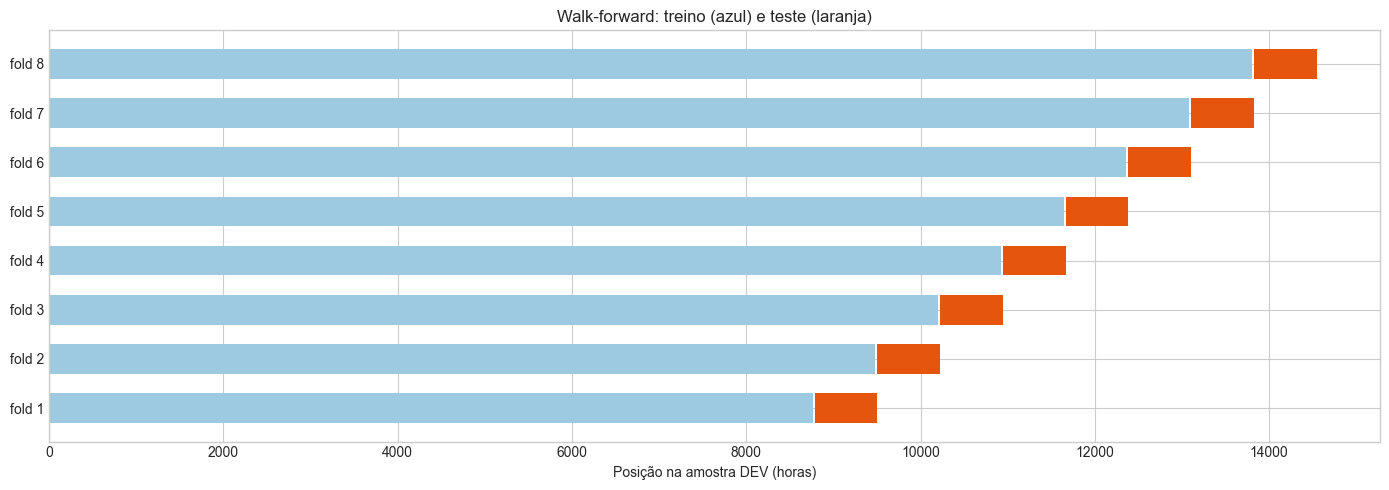

In [8]:
n = len(df_all)
hold_h = HOLDOUT_DIAS * 24
part = np.array(["dev"] * n, dtype=object)
part[:JANELA_REF_H] = "warmup"
part[n - hold_h - EMBARGO_H: n - hold_h] = "embargo"
part[n - hold_h:] = "holdout"
df_all["particao"] = part
print(df_all["particao"].value_counts().to_string())

dev = df_all[df_all["particao"] == "dev"].reset_index(drop=True)
print(f"\nDEV: {len(dev):,} h ({dev['hora'].min()} -> {dev['hora'].max()})")
print(f"HOLDOUT: {hold_h:,} h ({df_all.loc[df_all['particao'] == 'holdout', 'hora'].min()} -> {df_all['hora'].max()})")

def gerar_folds(n_dev, treino_ini_h, bloco_h, passo_h, embargo_h):
    folds, ini_teste = [], treino_ini_h + embargo_h
    while ini_teste + bloco_h <= n_dev:
        folds.append({"tr_ini": 0, "tr_fim": ini_teste - embargo_h, "te_ini": ini_teste, "te_fim": ini_teste + bloco_h})
        ini_teste += passo_h
    return folds

folds = gerar_folds(len(dev), TREINO_INICIAL_DIAS * 24, TESTE_BLOCO_DIAS * 24, PASSO_DIAS * 24, EMBARGO_H)
tab = pd.DataFrame(folds)
tab["fold"] = np.arange(1, len(tab) + 1)
tab["treino_ate"] = [dev["hora"].iloc[f["tr_fim"] - 1] for f in folds]
tab["teste_de"] = [dev["hora"].iloc[f["te_ini"]] for f in folds]
tab["teste_ate"] = [dev["hora"].iloc[f["te_fim"] - 1] for f in folds]
tab["horas_treino"] = tab["tr_fim"] - tab["tr_ini"]

# verificação de que nenhum rótulo de treino alcança o teste
for f in folds:
    ultimo_rotulo_treino = (f["tr_fim"] - 1) + max(HORIZONTES_VOL)
    assert ultimo_rotulo_treino < f["te_ini"], "Rótulo de treino invade o período de teste"
print(f"\n{len(folds)} folds walk-forward (rótulos de treino não alcançam o teste: verificado).")
display(tab[["fold", "horas_treino", "treino_ate", "teste_de", "teste_ate"]])

fig, ax = plt.subplots(figsize=(14, 3 + 0.25 * len(folds)))
for i, f in enumerate(folds):
    ax.barh(i, f["tr_fim"] - f["tr_ini"], left=f["tr_ini"], color="#9ecae1", height=0.6)
    ax.barh(i, f["te_fim"] - f["te_ini"], left=f["te_ini"], color="#e6550d", height=0.6)
ax.set_yticks(range(len(folds))); ax.set_yticklabels([f"fold {i+1}" for i in range(len(folds))])
ax.set_xlabel("Posição na amostra DEV (horas)"); ax.set_title("Walk-forward: treino (azul) e teste (laranja)")
plt.tight_layout(); plt.show()

## 7. Análises exploratórias corrigidas (apenas `dev`)

### 7.1 Lead-lag com pré-branqueamento e Granger com erros robustos

Correlação cruzada entre séries autocorrelacionadas gera padrões espúrios. Aqui cada série é **pré-branqueada** (resíduos de um AR(24)) antes da correlação cruzada, e a comparação com a versão *crua* mostra quanto da estrutura era artefato. Em seguida, um teste de Granger (Wald com covariância de Newey–West) nas duas direções.

Ressalva: precedência estatística não é causalidade, e a agregação horária impede ordenar eventos dentro da mesma hora.

BTC: lags com correlação pré-branqueada fora da banda: [-23, -14, -13, -12, -11, -9, -8, -1, 0, 1, 2, 3, 4, 6, 7, 9, 14, 18, 19, 21, 23]
ETH: lags com correlação pré-branqueada fora da banda: [-24, -23, -22, -21, -20, -14, -7, -6, -5, -4, -3, -2, -1, 0, 1, 3, 7, 10, 12, 13, 14, 15, 21, 23, 24]


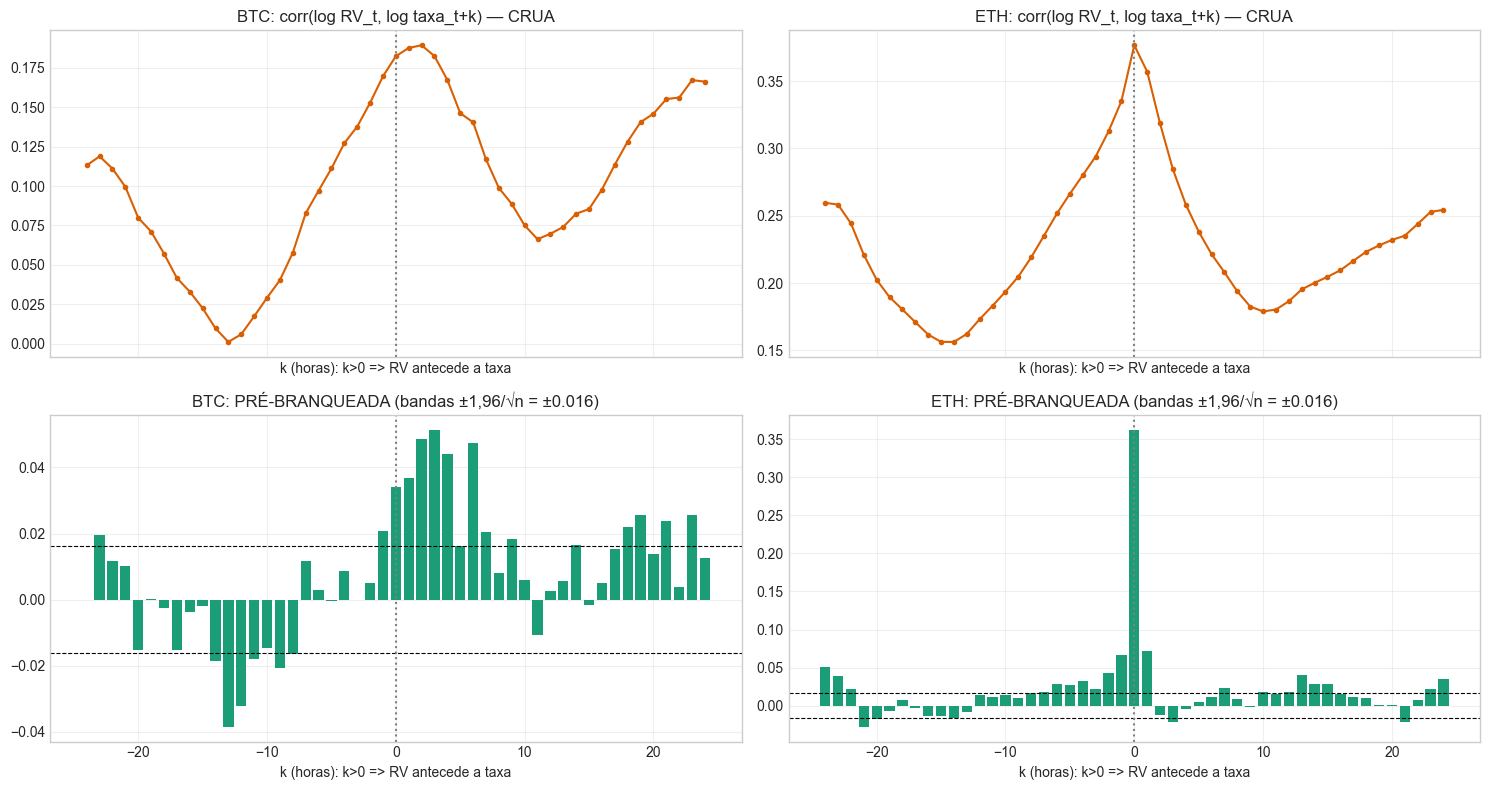


Teste de Granger (p=6 defasagens, Newey-West L=24):


,rede,direção,Wald,p_valor,soma_coef_x,n
0,BTC,log RV -> Δ log taxa,44.9074,0.0000,0.0479,14609
1,BTC,Δ log taxa -> log RV,15.7497,0.0152,-0.0738,14609
2,ETH,log RV -> Δ log taxa,148.2668,0.0000,-0.0536,14609
3,ETH,Δ log taxa -> log RV,64.1095,0.0000,0.0360,14609


In [9]:
def ols_hac(y, X, L):
    # OLS com intercepto e covariância de Newey-West (kernel de Bartlett)
    X = np.column_stack([np.ones(len(y)), X]) if X.size else np.ones((len(y), 1))
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ beta
    XtX_inv = np.linalg.inv(X.T @ X)
    Xe = X * e[:, None]
    S = Xe.T @ Xe
    for l in range(1, L + 1):
        w = 1 - l / (L + 1)
        G = Xe[l:].T @ Xe[:-l]
        S += w * (G + G.T)
    V = XtX_inv @ S @ XtX_inv
    return beta, V

def wald(beta, V, idx):
    b = beta[idx]
    Vb = V[np.ix_(idx, idx)]
    W = float(b @ np.linalg.solve(Vb, b))
    return W, float(stats.chi2.sf(W, len(idx)))

def ar_residuos(x, p=24):
    x = np.asarray(x, float)
    n = len(x)
    y = x[p:]
    X = np.column_stack([np.ones(n - p)] + [x[p - i: n - i] for i in range(1, p + 1)])
    ok = np.isfinite(y) & np.isfinite(X).all(axis=1)
    beta = np.linalg.lstsq(X[ok], y[ok], rcond=None)[0]
    res = np.full(n, np.nan)
    res[p:][ok] = (y - X @ beta)[ok]
    return res

def ccf(a, b, ks):
    out, ns = [], []
    for k in ks:
        if k >= 0:
            x, y = a[:len(a) - k], b[k:]
        else:
            x, y = a[-k:], b[:len(b) + k]
        m = np.isfinite(x) & np.isfinite(y)
        out.append(np.corrcoef(x[m], y[m])[0, 1] if m.sum() > 30 else np.nan)
        ns.append(int(m.sum()))
    return np.array(out), int(np.median(ns))

ks = np.arange(-24, 25)
pares = {"btc": ("btc_lrv", "btc_lfee_p50"), "eth": ("eth_lrv", "eth_lbase")}
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for j, (a, (cv, cf)) in enumerate(pares.items()):
    v, f = dev[cv].to_numpy(float), dev[cf].to_numpy(float)
    c_cru, n_cru = ccf(v, f, ks)
    c_bra, n_bra = ccf(ar_residuos(v), ar_residuos(f), ks)
    banda = 1.96 / np.sqrt(n_bra)
    axes[0, j].plot(ks, c_cru, "o-", color="#d95f02", ms=3); axes[0, j].set_title(f"{a.upper()}: corr(log RV_t, log taxa_t+k) — CRUA")
    axes[1, j].bar(ks, c_bra, color="#1b9e77"); axes[1, j].axhline(banda, color="k", ls="--", lw=0.8); axes[1, j].axhline(-banda, color="k", ls="--", lw=0.8)
    axes[1, j].set_title(f"{a.upper()}: PRÉ-BRANQUEADA (bandas ±1,96/√n = ±{banda:.3f})")
    for ax in (axes[0, j], axes[1, j]):
        ax.axvline(0, color="gray", ls=":"); ax.set_xlabel("k (horas): k>0 => RV antecede a taxa"); ax.grid(True, alpha=0.3)
    sig = [int(k) for k, c in zip(ks, c_bra) if abs(c) > banda]
    print(f"{a.upper()}: lags com correlação pré-branqueada fora da banda: {sig}")
plt.tight_layout(); plt.show()

# ---- Granger (Wald HAC) nas duas direções ----
def granger_hac(y, x, extra, p=6, L=24):
    n = len(y)
    Y = y[p:]
    Z = np.column_stack([y[p - i: n - i] for i in range(1, p + 1)] + [x[p - i: n - i] for i in range(1, p + 1)] + [extra[p:]])
    ok = np.isfinite(Y) & np.isfinite(Z).all(axis=1)
    beta, V = ols_hac(Y[ok], Z[ok], L)
    idx = list(range(1 + p, 1 + 2 * p))
    W, pv = wald(beta, V, idx)
    return {"Wald": W, "p_valor": pv, "soma_coef_x": float(beta[idx].sum()), "n": int(ok.sum())}

linhas = []
extra = dev[["cal_sin", "cal_cos"]].to_numpy(float)
for a, (cv, cf) in pares.items():
    lrv = dev[cv].to_numpy(float)
    dfee = dev[cf].diff().to_numpy(float)
    r1 = granger_hac(dfee, lrv, extra); r2 = granger_hac(lrv, dfee, extra)
    linhas.append({"rede": a.upper(), "direção": "log RV  ->  Δ log taxa", **r1})
    linhas.append({"rede": a.upper(), "direção": "Δ log taxa  ->  log RV", **r2})
print("\nTeste de Granger (p=6 defasagens, Newey-West L=24):")
display(pd.DataFrame(linhas).round(4))

### 7.2 Estudo de evento: as N maiores explosões de volatilidade

Em vez de um episódio, usa-se as **N maiores horas de RV** (separadas por pelo menos 24 h). Para cada uma, mede-se a variação da **log-taxa** em relação ao seu nível 13–24 h antes. O **placebo** sorteia horas aleatórias com a **mesma hora do dia** dos eventos, e a banda cinza é o intervalo de 95% do que se esperaria por acaso.

BTC: horas relativas (k) em que a taxa média sai da banda do placebo: [6, 7]
ETH: horas relativas (k) em que a taxa média sai da banda do placebo: [-4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


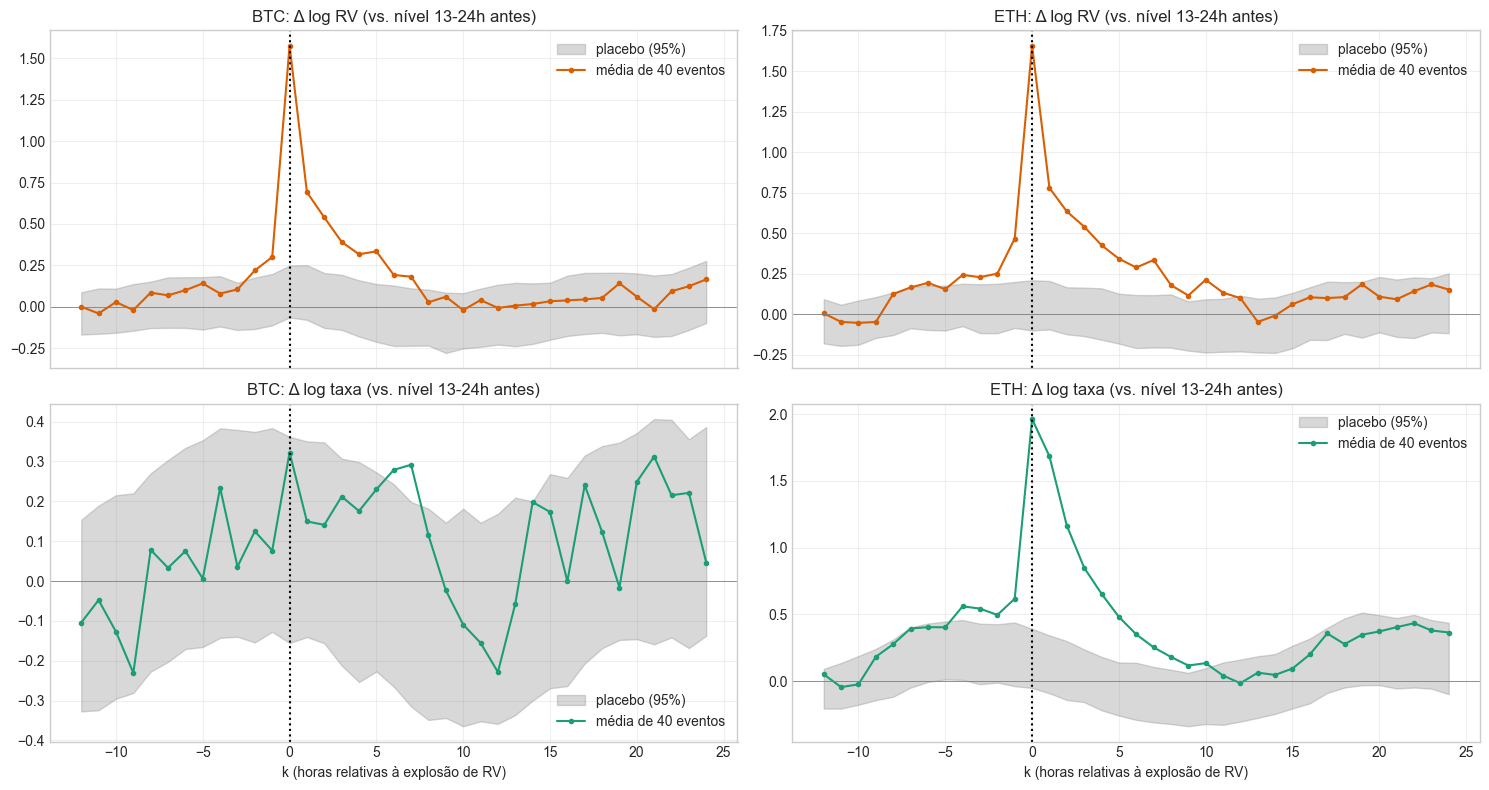


BTC — 10 maiores eventos de RV e reação da taxa:


,RV_%,Δlog_taxa_k+1,Δlog_taxa_k+3,Δlog_taxa_k+6
hora_evento,,,,
2025-10-10 21:00:00+00:00,9.507,1.671,1.097,0.755
2025-01-20 17:00:00+00:00,4.708,0.892,0.963,0.883
2024-12-05 22:00:00+00:00,4.562,0.435,0.117,-0.017
2026-02-06 00:00:00+00:00,4.102,1.270,1.557,1.457
2026-03-23 11:00:00+00:00,3.930,-1.535,1.040,1.035
2025-04-07 14:00:00+00:00,3.187,0.434,1.282,0.151
2025-03-02 16:00:00+00:00,2.962,0.361,0.636,0.165
2025-03-07 00:00:00+00:00,2.948,0.103,-0.162,0.088
2025-04-09 17:00:00+00:00,2.877,0.101,0.030,0.032



ETH — 10 maiores eventos de RV e reação da taxa:


,RV_%,Δlog_taxa_k+1,Δlog_taxa_k+3,Δlog_taxa_k+6
hora_evento,,,,
2025-10-10 21:00:00+00:00,10.272,6.570,4.753,2.792
2025-02-03 02:00:00+00:00,8.077,3.762,2.394,1.776
2025-03-02 16:00:00+00:00,7.128,3.652,1.290,0.376
2024-12-09 21:00:00+00:00,5.841,1.585,0.908,0.909
2026-03-23 11:00:00+00:00,5.386,1.443,1.394,0.771
2025-06-21 21:00:00+00:00,4.865,1.890,1.755,0.074
2026-02-06 00:00:00+00:00,4.659,2.758,0.985,1.149
2025-04-09 17:00:00+00:00,4.518,3.534,1.033,-0.442
2025-05-09 08:00:00+00:00,4.433,0.833,-0.546,0.320


In [10]:
def selecionar_eventos(score, n_ev, sep, margem_ini, margem_fim):
    s = np.asarray(score, float).copy()
    s[~np.isfinite(s)] = -np.inf
    s[:margem_ini] = -np.inf
    s[len(s) - margem_fim:] = -np.inf
    ordem = np.argsort(-s)
    esc = []
    for i in ordem:
        if not np.isfinite(s[i]) or len(esc) >= n_ev:
            break
        if all(abs(i - j) >= sep for j in esc):
            esc.append(int(i))
    return np.array(esc)

def matriz_curvas(serie, K):
    x = np.asarray(serie, float)
    n = len(x)
    C = np.full((n, len(K)), np.nan)
    for j, k in enumerate(K):
        idx = np.arange(n) + k
        ok = (idx >= 0) & (idx < n)
        C[ok, j] = x[idx[ok]]
    base = pd.Series(x).shift(13).rolling(12, min_periods=8).mean().to_numpy()
    return C - base[:, None]

K = np.arange(-12, 25)
hora_dia = dev["hora"].dt.hour.to_numpy()
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
tabelas_eventos = {}
for j, (a, (cv, cf)) in enumerate(pares.items()):
    ev = selecionar_eventos(dev[cv], N_EVENTOS, 24, 24, 30)
    proibidos = np.zeros(len(dev), bool)
    for e in ev:
        proibidos[max(0, e - 24): e + 25] = True
    pool = {h: np.where((hora_dia == h) & ~proibidos)[0] for h in range(24)}
    pool = {h: v[(v >= 24) & (v < len(dev) - 30)] for h, v in pool.items()}
    for i, (serie, titulo) in enumerate([(dev[cv], "Δ log RV (vs. nível 13-24h antes)"), (dev[cf], "Δ log taxa (vs. nível 13-24h antes)")]):
        C = matriz_curvas(serie, K)
        media_ev = np.nanmean(C[ev], axis=0)
        sim = np.empty((B_PERM, len(K)))
        for b in range(B_PERM):
            sorteio = np.array([rng.choice(pool[hora_dia[e]]) for e in ev])
            sim[b] = np.nanmean(C[sorteio], axis=0)
        lo, hi = np.percentile(sim, [2.5, 97.5], axis=0)
        ax = axes[i, j]
        ax.fill_between(K, lo, hi, color="gray", alpha=0.3, label="placebo (95%)")
        ax.plot(K, media_ev, "o-", color="#d95f02" if i == 0 else "#1b9e77", ms=3, label=f"média de {len(ev)} eventos")
        ax.axvline(0, color="k", ls=":"); ax.axhline(0, color="gray", lw=0.6)
        ax.set_title(f"{a.upper()}: {titulo}"); ax.grid(True, alpha=0.3); ax.legend()
        if i == 1:
            fora = [int(k) for k, m, l_, h_ in zip(K, media_ev, lo, hi) if (m > h_ or m < l_)]
            print(f"{a.upper()}: horas relativas (k) em que a taxa média sai da banda do placebo: {fora}")
    for ax in axes[1]:
        ax.set_xlabel("k (horas relativas à explosão de RV)")
    Cf = matriz_curvas(dev[cf], K)
    tb = pd.DataFrame({"hora_evento": dev["hora"].iloc[ev].to_numpy(), "RV_%": np.exp(dev[cv].iloc[ev].to_numpy()) * 100,
                       "Δlog_taxa_k+1": Cf[ev, list(K).index(1)], "Δlog_taxa_k+3": Cf[ev, list(K).index(3)], "Δlog_taxa_k+6": Cf[ev, list(K).index(6)]})
    tabelas_eventos[a] = tb.sort_values("RV_%", ascending=False)
plt.tight_layout(); plt.show()
for a, tb in tabelas_eventos.items():
    print(f"\n{a.upper()} — 10 maiores eventos de RV e reação da taxa:")
    display(tb.head(10).set_index("hora_evento").round(3))

### 7.3 Lift preditivo com incerteza

Agora o lift é **preditivo**: `P(evento de taxa em t+1…t+h | vol alta em t) / P(evento)`. A "vol alta" usa o quantil dos **últimos 30 dias** (só passado). Três salvaguardas:

- **IC 95% por *bootstrap* em blocos** de 48 h (preserva autocorrelação);
- **p-valor por permutação estratificada** por hora do dia × mês (embaralha o evento dentro do estrato, o que remove sazonalidade intradiária e mudanças de regime);
- Lift = 1 significa independência.

In [11]:
dev["hora_dia"] = dev["hora"].dt.hour
dev["estrato"] = pd.factorize(dev["hora_dia"].astype(str) + "_" + dev["hora"].dt.strftime("%Y-%m"))[0]

def lift_com_incerteza(vol_alta, evento, estratos, bloco=48):
    m = np.isfinite(vol_alta) & np.isfinite(evento)
    v = vol_alta[m].astype(bool); e = evento[m].astype(bool); s = estratos[m]
    if e.sum() < 5 or v.sum() < 5:
        return None
    base = e.mean(); cond = e[v].mean(); lift = cond / base
    n = len(e); nb = int(np.ceil(n / bloco))
    starts = rng.integers(0, n - bloco + 1, size=(B_BOOT, nb)).astype(np.int32)
    idx = (starts[:, :, None] + np.arange(bloco, dtype=np.int32)).reshape(B_BOOT, -1)[:, :n]
    eb, vb = e[idx], v[idx]
    nv = vb.sum(axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        lb = ((eb & vb).sum(axis=1) / nv) / eb.mean(axis=1)
    lb = lb[np.isfinite(lb)]
    grupos = [np.where(s == g)[0] for g in np.unique(s)]
    lp = np.empty(B_PERM)
    for b in range(B_PERM):
        ep = e.copy()
        for g in grupos:
            ep[g] = e[g][rng.permutation(len(g))]
        lp[b] = (ep[v].mean() / ep.mean()) if ep.mean() > 0 else np.nan
    p = (1 + np.nansum(lp >= lift)) / (np.sum(np.isfinite(lp)) + 1)
    return {"n": int(m.sum()), "taxa_base": base, "P(ev|vol alta)": cond, "lift": lift,
            "IC95_inf": np.percentile(lb, 2.5), "IC95_sup": np.percentile(lb, 97.5), "p_perm": p}

linhas = []
for a in ("btc", "eth"):
    va = dev[f"{a}_vol_alta"].to_numpy(float)
    for tipo in ("q", "x"):
        for h in HORIZONTES_TAXA:
            ev = dev[f"y_{a}_ev_{tipo}_{h}h"].to_numpy(float)
            r = lift_com_incerteza(va, ev, dev["estrato"].to_numpy())
            if r is not None:
                linhas.append({"rede": a.upper(), "evento": f"ev_{tipo}", "h": h, **r})
lift_tab = pd.DataFrame(linhas)
print("Lift preditivo (vol alta em t -> evento de taxa em t+1…t+h), apenas DEV:")
display(lift_tab.round(4))

Lift preditivo (vol alta em t -> evento de taxa em t+1…t+h), apenas DEV:


,rede,evento,h,n,taxa_base,P(ev|vol alta),lift,IC95_inf,IC95_sup,p_perm
0,BTC,ev_q,1,14616,0.0886,0.1764,1.9913,1.6219,2.3140,0.002
1,BTC,ev_q,6,14616,0.2634,0.4188,1.5898,1.4205,1.7554,0.002
2,BTC,ev_x,1,14616,0.1616,0.2437,1.5079,1.3135,1.6902,0.002
3,BTC,ev_x,6,14616,0.4115,0.5033,1.2233,1.0916,1.3305,0.002
4,ETH,ev_q,1,14616,0.0951,0.3556,3.7390,3.3580,4.1759,0.002
5,ETH,ev_q,6,14616,0.2133,0.4831,2.2655,2.0851,2.4891,0.002
6,ETH,ev_x,1,14616,0.2195,0.5843,2.6620,2.4585,2.8906,0.002
7,ETH,ev_x,6,14616,0.3994,0.6946,1.7394,1.6364,1.8442,0.002


### 7.4 Fear & Greed no nível diário

O índice tem **um valor por dia**, então o tamanho amostral relevante é o número de dias. A análise agrega a volatilidade e a taxa por dia e usa o F&G defasado. Também mede a **circularidade**: o F&G publicado inclui componentes de volatilidade e momentum, então ele deveria correlacionar com a volatilidade *passada* recente.

In [12]:
dd = dev.copy()
dd["dia"] = dd["hora"].dt.floor("D")
linhas = []
for a, (cv, cf) in pares.items():
    d = dd.groupby("dia").agg(lrv=(cv, "mean"), lfee=(cf, "mean"), fng=("fng_lag1", "first"),
                              lrv_w_ini=(f"{a}_lrv_w", "first"), fng_var7=("fng_var7", "first")).dropna()
    d["lrv_fut"] = d["lrv"].shift(-1)          # volatilidade média do dia seguinte
    d["lfee_fut"] = d["lfee"].shift(-1)
    for nome, x, y in [("F&G(t-1) vs log RV médio do dia", d["fng"], d["lrv"]),
                       ("F&G(t-1) vs log taxa média do dia", d["fng"], d["lfee"]),
                       ("F&G(t-1) vs log RV do dia SEGUINTE", d["fng"], d["lrv_fut"]),
                       ("Circularidade: F&G(t-1) vs RV semanal passada", d["fng"], d["lrv_w_ini"])]:
        m = x.notna() & y.notna()
        rho, p = stats.spearmanr(x[m], y[m])
        linhas.append({"rede": a.upper(), "relação": nome, "n_dias": int(m.sum()), "Spearman": rho, "p_valor": p})
print("Associações no nível DIÁRIO (n = dias, não horas). Obs.: séries autocorrelacionadas -> p-valores otimistas.")
display(pd.DataFrame(linhas).round(4))

cont = dd.drop_duplicates("dia")["fng_class_lag1"].value_counts()
print("\nDias por classe do F&G (defasado) no DEV:")
display(cont.to_frame("dias"))

Associações no nível DIÁRIO (n = dias, não horas). Obs.: séries autocorrelacionadas -> p-valores otimistas.


,rede,relação,n_dias,Spearman,p_valor
0,BTC,F&G(t-1) vs log RV médio do dia,609,-0.2259,0.0000
1,BTC,F&G(t-1) vs log taxa média do dia,609,0.6446,0.0000
2,BTC,F&G(t-1) vs log RV do dia SEGUINTE,608,-0.2157,0.0000
3,BTC,Circularidade: F&G(t-1) vs RV semanal passada,609,-0.3446,0.0000
4,ETH,F&G(t-1) vs log RV médio do dia,609,0.0525,0.1957
5,ETH,F&G(t-1) vs log taxa média do dia,609,0.7381,0.0000
6,ETH,F&G(t-1) vs log RV do dia SEGUINTE,608,0.0631,0.1204
7,ETH,Circularidade: F&G(t-1) vs RV semanal passada,609,-0.0466,0.2506



Dias por classe do F&G (defasado) no DEV:


,dias
fng_class_lag1,
Extreme Fear,201
Greed,159
Fear,154
Neutral,70
Extreme Greed,25


## 8. Escada de modelos de volatilidade (HAR → HAR-X)

Cada degrau acrescenta **um bloco de informação**, para isolar quanto cada fonte agrega:

| Modelo | Variáveis |
|---|---|
| M0 | ingênuo: volatilidade das últimas 24 h |
| M1 | HAR: log RV (1h, 24h, 168h) |
| M2 | M1 + calendário (hora do dia, fim de semana) |
| M3 | M2 + mercado (retornos, volume relativo) |
| M4 | M3 + **on-chain** (taxas, vsize, base fee, uso de gás) |
| M5 | M4 + **Fear & Greed** |

Previsão em log (`log RV` futuro). **QLIKE** é calculada na escala da variância (`RV² real` vs. `variância prevista = exp(2ŷ + 2s²)`, com `s²` o resíduo de treino). O teste de **Diebold–Mariano** usa erro-padrão de Newey–West; os p-valores recebem **correção de Holm**. Somente os folds de `dev` são usados.

In [13]:
def conjuntos(a):
    har = [f"{a}_lrv", f"{a}_lrv_d", f"{a}_lrv_w"]
    cal = ["cal_sin", "cal_cos", "cal_fim_semana"]
    mkt = [f"{a}_ret_1h", f"{a}_ret_neg_24h", f"{a}_lvol_rel"]
    if a == "btc":
        rede = ["btc_lfee_p50", "btc_lfee_p90", "btc_lvsize", "btc_ltx", "btc_hora_sem_bloco", "btc_lfee_rel30d"]
    else:
        rede = ["eth_lbase", "eth_lprio", "eth_gas_ratio_c", "eth_ltx", "eth_lbase_rel30d"]
    sent = ["fng_lag1", "fng_var7"]
    return {"M1": har, "M2": har + cal, "M3": har + cal + mkt, "M4": har + cal + mkt + rede, "M5": har + cal + mkt + rede + sent}

def ols_fit(X, y):
    A = np.column_stack([np.ones(len(X)), X])
    beta = np.linalg.lstsq(A, y, rcond=None)[0]
    res = y - A @ beta
    return beta, float(res.var(ddof=A.shape[1]))

def ols_pred(beta, X):
    return np.column_stack([np.ones(len(X)), X]) @ beta

def qlike(r, f):
    q = r / f
    return q - np.log(q) - 1

def holm(p):
    p = np.asarray(p, float)
    ordem = np.argsort(p); ajust = np.empty(len(p)); corrente = 0.0
    for rank, i in enumerate(ordem):
        corrente = max(corrente, (len(p) - rank) * p[i]); ajust[i] = min(1.0, corrente)
    return ajust

def dm_hac(d, L):
    beta, V = ols_hac(d, np.empty((len(d), 0)), L)
    t = beta[0] / np.sqrt(V[0, 0])
    return float(t), float(2 * stats.norm.sf(abs(t)))

def rodar_escada(a, h):
    ycol = f"y_{a}_lrv_{h}h"
    cj = conjuntos(a)
    cols_todas = cj["M5"] + [ycol]
    preds = []
    for k, f in enumerate(folds):
        tr = dev.iloc[f["tr_ini"]:f["tr_fim"]]; te = dev.iloc[f["te_ini"]:f["te_fim"]]
        tr = tr.dropna(subset=cols_todas); te = te.dropna(subset=cols_todas)
        reg = {"hora": te["hora"].to_numpy(), "fold": k + 1, "y": te[ycol].to_numpy()}
        # M0: ingênuo
        y0_tr = tr[f"{a}_lrv_d"].to_numpy() + 0.5 * np.log(h)
        s2_0 = float(np.var(tr[ycol].to_numpy() - y0_tr, ddof=1))
        reg["yhat_M0"] = te[f"{a}_lrv_d"].to_numpy() + 0.5 * np.log(h); reg["s2_M0"] = s2_0
        for nome, cols in cj.items():
            beta, s2 = ols_fit(tr[cols].to_numpy(float), tr[ycol].to_numpy(float))
            reg[f"yhat_{nome}"] = ols_pred(beta, te[cols].to_numpy(float)); reg[f"s2_{nome}"] = s2
        preds.append(pd.DataFrame(reg))
    P = pd.concat(preds, ignore_index=True)
    r = np.exp(2 * P["y"].to_numpy())
    for nome in ["M0"] + list(cj):
        F = np.exp(2 * P[f"yhat_{nome}"].to_numpy() + 2 * P[f"s2_{nome}"].to_numpy())
        P[f"ql_{nome}"] = qlike(r, F)
        P[f"erro_{nome}"] = P["y"] - P[f"yhat_{nome}"]
    return P

resumo_ql, resumo_inc = [], []
for a in ("btc", "eth"):
    for h in HORIZONTES_VOL:
        P = rodar_escada(a, h)
        modelos = ["M0", "M1", "M2", "M3", "M4", "M5"]
        linha = {"rede": a.upper(), "h": h, "n_teste": len(P)}
        for m_ in modelos:
            linha[f"QLIKE_{m_}"] = P[f"ql_{m_}"].mean()
        linha["RMSE_log_M1"] = float(np.sqrt((P["erro_M1"] ** 2).mean()))
        linha["RMSE_log_M5"] = float(np.sqrt((P["erro_M5"] ** 2).mean()))
        resumo_ql.append(linha)
        for ant, nov, rot in [("M1", "M2", "+calendário"), ("M2", "M3", "+mercado"), ("M3", "M4", "+on-chain"), ("M4", "M5", "+Fear&Greed"), ("M2", "M5", "tudo vs M2")]:
            d = (P[f"ql_{ant}"] - P[f"ql_{nov}"]).to_numpy()
            t, p = dm_hac(d, L=max(24, h) + h)
            por_fold = P.groupby("fold").apply(lambda g: (g[f"ql_{ant}"].mean() > g[f"ql_{nov}"].mean())).sum()
            resumo_inc.append({"rede": a.upper(), "h": h, "degrau": rot, "ganho_QLIKE_%": 100 * d.mean() / P[f"ql_{ant}"].mean(),
                               "DM_t": t, "p_valor": p, "folds_melhores": f"{int(por_fold)}/{P['fold'].nunique()}"})

tab_ql = pd.DataFrame(resumo_ql)
tab_inc = pd.DataFrame(resumo_inc)
tab_inc["p_Holm"] = holm(tab_inc["p_valor"].to_numpy())
print("QLIKE médio fora da amostra (menor = melhor), folds walk-forward de DEV:")
display(tab_ql.round(4))
print("\nGanho incremental de cada degrau (QLIKE > 0 = melhora) com Diebold-Mariano (HAC) e Holm:")
display(tab_inc.round(4))

QLIKE médio fora da amostra (menor = melhor), folds walk-forward de DEV:


,rede,h,n_teste,QLIKE_M0,QLIKE_M1,QLIKE_M2,QLIKE_M3,QLIKE_M4,QLIKE_M5,RMSE_log_M1,RMSE_log_M5
0,BTC,1,5760,0.6652,0.4631,0.4513,0.4463,0.4517,0.4509,0.4353,0.4243
1,BTC,4,5760,0.4724,0.3600,0.3373,0.3335,0.3356,0.3349,0.3971,0.3782
2,BTC,12,5760,0.3652,0.2609,0.2483,0.2438,0.2450,0.2444,0.3648,0.3395
3,BTC,24,5760,0.3449,0.1948,0.2002,0.1917,0.1926,0.1913,0.3250,0.3183
4,ETH,1,5760,0.6947,0.5260,0.5125,0.5085,0.5160,0.5181,0.4581,0.4458
5,ETH,4,5760,0.4720,0.3794,0.3579,0.3529,0.3582,0.3604,0.4090,0.3933
6,ETH,12,5760,0.3487,0.2623,0.2484,0.2444,0.2483,0.2500,0.3670,0.3504
7,ETH,24,5760,0.3148,0.1964,0.1989,0.1929,0.1953,0.1977,0.3252,0.3258



Ganho incremental de cada degrau (QLIKE > 0 = melhora) com Diebold-Mariano (HAC) e Holm:


,rede,h,degrau,ganho_QLIKE_%,DM_t,p_valor,folds_melhores,p_Holm
0,BTC,1,+calendário,2.5309,2.7472,0.0060,7/8,0.2032
1,BTC,1,+mercado,1.1248,0.8830,0.3773,5/8,1.0000
2,BTC,1,+on-chain,-1.2172,-4.3326,0.0000,1/8,0.0006
3,BTC,1,+Fear&Greed,0.1822,0.8469,0.3970,5/8,1.0000
4,BTC,1,tudo vs M2,0.1037,0.0755,0.9398,4/8,1.0000
5,BTC,4,+calendário,6.3242,2.7490,0.0060,7/8,0.2032
6,BTC,4,+mercado,1.1302,1.1276,0.2595,4/8,1.0000
7,BTC,4,+on-chain,-0.6293,-1.9031,0.0570,3/8,1.0000
8,BTC,4,+Fear&Greed,0.2079,0.5391,0.5898,3/8,1.0000
9,BTC,4,tudo vs M2,0.7149,0.6369,0.5242,5/8,1.0000


## 9. Saídas para a modelagem

Grava o dataset completo (com a coluna `particao`), os folds e um arquivo de metadados com a definição de cada grupo de variáveis e alvos. **O *holdout* está no arquivo, mas marcado, e não deve ser usado até o fim.**

In [14]:
cols_alvo = [c for c in df_all.columns if c.startswith("y_")]
meta = {
    "periodo": [str(df_all["hora"].min()), str(df_all["hora"].max())],
    "linhas": int(len(df_all)),
    "particoes": df_all["particao"].value_counts().to_dict(),
    "parametros": {"HORIZONTES_VOL": HORIZONTES_VOL, "HORIZONTES_TAXA": HORIZONTES_TAXA, "JANELA_REF_H": JANELA_REF_H,
                   "Q_ALTO": Q_ALTO, "MULT_MEDIANA": MULT_MEDIANA, "EMBARGO_H": EMBARGO_H, "HOLDOUT_DIAS": HOLDOUT_DIAS},
    "alvos_volatilidade": [c for c in cols_alvo if "_lrv_" in c],
    "alvos_taxa_continuos": [c for c in cols_alvo if "_lfee_max_" in c],
    "alvos_taxa_eventos": [c for c in cols_alvo if "_ev_" in c],
    "features_por_modelo": {a: conjuntos(a) for a in ("btc", "eth")},
    "convencao_temporal": "hora = inicio da janela; linha disponivel em hora+1h; alvos olham de t+1 em diante",
}
df_all.to_csv(PASTA_SAIDA / "dataset_modelagem.csv", index=False)
tab.to_csv(PASTA_SAIDA / "folds_walkforward.csv", index=False)
tab_ql.to_csv(PASTA_SAIDA / "resultado_escada_qlike.csv", index=False)
tab_inc.to_csv(PASTA_SAIDA / "resultado_escada_incremental.csv", index=False)
with open(PASTA_SAIDA / "metadados_modelagem.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

print("Arquivos salvos em:", PASTA_SAIDA)
for nome in ["dataset_modelagem.csv", "folds_walkforward.csv", "resultado_escada_qlike.csv", "resultado_escada_incremental.csv", "metadados_modelagem.json"]:
    print(" -", nome, f"({(PASTA_SAIDA / nome).stat().st_size / 1024:,.0f} KB)")
print(f"\nColunas: {df_all.shape[1]} | alvos: {len(cols_alvo)} | linhas por partição:")
print(df_all['particao'].value_counts().to_string())

Arquivos salvos em: /home/alisson/datathon fgv/Análises/modelagem
 - dataset_modelagem.csv (27,265 KB)
 - folds_walkforward.csv (1 KB)
 - resultado_escada_qlike.csv (1 KB)
 - resultado_escada_incremental.csv (4 KB)
 - metadados_modelagem.json (3 KB)

Colunas: 113 | alvos: 20 | linhas por partição:
particao
dev        14616
holdout     2160
warmup       720
embargo       24


## Próximos passos (modelagem)

1. **Ler as tabelas da seção 8 e da 7.x antes de decidir qualquer coisa.** Se `p_Holm` não rejeitar para M4 e M5, a conclusão honesta é que on-chain e Fear & Greed não agregam ao HAR nesta amostra.
2. **Incorporar o sentimento textual** (GDELT em 15 min, notebook 03_BigQuery) como degrau M6. É o teste real da hipótese central, pois o Fear & Greed é diário e parcialmente endógeno.
3. **Modelo B**: logística/Ridge para `y_*_ev_*` com os mesmos folds, avaliada por PR-AUC com a prevalência como referência, calibração e Brier score. Comparar `ev_q` e `ev_x`.
4. **Árvores** (Random Forest / Gradient Boosting) só depois de ter o baseline linear.
5. **Abrir o *holdout* uma única vez**, com o modelo e os hiperparâmetros já congelados.